# Benchmark plots

Reads the CSVs produced by `run_ip.sh`, `run_dt_rows.sh`, `run_dt_cols.sh`
and draws paper-ready figures, saving each as a PDF under `figures/`.

**IP and DT are kept in separate figures** — a set of `ip_*` figures for the
exact integer program and a set of `dt_*` figures for the decision-tree
approach (the two DT query types share a figure since both are DT).

Every config was run with warm-ups + several recorded repeats, so each point
is the **mean over reps** with a **±std** error bar.

## Design language (fonts, sizing, palette)

In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Custom font (Linux Libertine).  Falls back to the default if the TTF is absent.
font_path = './fonts/LinLibertineTTF/LinLibertine_Rah.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    custom_font = fm.FontProperties(fname=font_path).get_name()
else:
    custom_font = plt.rcParams['font.family'][0]
    print(f"[warn] font not found at {font_path}; using '{custom_font}'")

width_pt = 241.14749
inches_per_pt = 1.0 / 72.27
fig_width = width_pt * inches_per_pt
fig_height = fig_width * 0.77

plt.rcParams.update({
    'font.family': custom_font,
    'font.size': 12,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'lines.linewidth': 3,
    'lines.markersize': 5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

CB_palette = {
    # Base
    'CBblue': (68/255, 119/255, 170/255),
    'CBcyan': (102/255, 204/255, 238/255),
    'CBgreen': (34/255, 136/255, 51/255),
    'CByellow': (204/255, 187/255, 68/255),
    'CBred': (238/255, 102/255, 119/255),
    'CBpurple': (170/255, 51/255, 119/255),
    'CBgrey': (187/255, 187/255, 187/255),
    'CBorange': (213/255, 94/255, 0/255),
    'CBsand': (221/255, 204/255, 119/255),
    'CBteal': (68/255, 170/255, 153/255),
    'CBolive': (170/255, 170/255, 0/255),
    # Pale
    'CBpaleblue': (187/255, 204/255, 238/255),
    'CBpalecyan': (204/255, 238/255, 255/255),
    'CBpalegreen': (204/255, 221/255, 170/255),
    'CBpaleyellow': (238/255, 238/255, 187/255),
    'CBpalered': (255/255, 204/255, 204/255),
    'CBpalegrey': (221/255, 221/255, 221/255),
    # Dark
    'CBdarkblue': (34/255, 34/255, 85/255),
    'CBdarkcyan': (34/255, 85/255, 85/255),
    'CBdarkgreen': (34/255, 85/255, 34/255),
    'CBdarkyellow': (102/255, 102/255, 51/255),
    'CBdarkred': (102/255, 51/255, 51/255),
    'CBdarkgrey': (85/255, 85/255, 85/255),
    'CBdarkindigo': (51/255, 34/255, 102/255),
}
cb_color_list = list(CB_palette.values())

## Load data + helpers

Point these paths at the CSVs your sweep scripts wrote.  Missing files are
skipped, so you can plot whichever experiments you have run so far.

In [16]:
OUTDIR = 'figures'
os.makedirs(OUTDIR, exist_ok=True)

PATHS = dict(
    ip='ip_results.csv',                               # run_ip.sh
    agn_rows='dt_rule_length_agnostic_rows.csv',       # run_dt_rows.sh
    fix_rows='dt_rule_length_fixed_rows.csv',          # run_dt_rows.sh
    agn_cols='dt_rule_length_agnostic_cols.csv',       # run_dt_cols.sh
    fix_cols='dt_rule_length_fixed_cols.csv',          # run_dt_cols.sh
)

def load(path):
    if os.path.exists(path):
        return pd.read_csv(path)
    print(f"[skip] {path} not found")
    return None

data = {k: load(p) for k, p in PATHS.items()}

def agg(df, x, y):
    """Mean and std of column y over reps, grouped by x, sorted by x."""
    g = df.groupby(x)[y].agg(['mean', 'std']).reset_index().sort_values(x)
    return g[x].to_numpy(), g['mean'].to_numpy(), g['std'].fillna(0).to_numpy()

def series(ax, df, x, y, label, color, marker='o'):
    """Plot one mean+/-std series onto ax (no-op if df is None)."""
    if df is None:
        return
    xs, m, s = agg(df, x, y)
    ax.errorbar(xs, m, yerr=s, label=label, color=color, marker=marker,
                capsize=2, elinewidth=0.8)

def save(fig, name):
    fig.tight_layout(pad=0.3)
    fig.savefig(f'{OUTDIR}/{name}.pdf', bbox_inches='tight')
    print(f'saved {OUTDIR}/{name}.pdf')

# IP figures — exact integer program

The IP sweep varies rows only (columns fixed at 3, since column-wise sorting
needs a single column).

## IP Fig 1 — solve time vs rows

In [ ]:
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
series(ax, data['ip'], 'n_rows', 'solve_sec', 'IP (exact)', CB_palette['CBred'], 's')
ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlabel('rows $n$')
ax.set_ylabel('solve time (s)')
save(fig, 'ip_runtime_vs_rows')

## IP Fig 2 — islands vs rows

In [ ]:
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
series(ax, data['ip'], 'n_rows', 'islands', 'IP islands', CB_palette['CBred'], 's')
ax.set_xscale('log', base=2)
ax.set_xlabel('rows $n$')
ax.set_ylabel('number of islands')
save(fig, 'ip_islands_vs_rows')

# DT figures — decision-tree approach

Each DT figure overlays the two query types (rule-length agnostic and
rule-length fixed).  Rows sweep with columns fixed at 16; columns sweep with
rows fixed at 32000.

## DT Fig 1 — query time vs rows

In [ ]:
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
series(ax, data['agn_rows'], 'n_rows', 'query_sec', 'rule-len agnostic', CB_palette['CBblue'], 'o')
series(ax, data['fix_rows'], 'n_rows', 'query_sec', 'rule-len fixed', CB_palette['CBgreen'], '^')
ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlabel('rows $n$')
ax.set_ylabel('query time (s)')
ax.legend(frameon=False)
save(fig, 'dt_runtime_vs_rows')

## DT Fig 2 — index build time vs rows

In [ ]:
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
series(ax, data['agn_rows'], 'n_rows', 'build_sec', 'rule-len agnostic', CB_palette['CBblue'], 'o')
series(ax, data['fix_rows'], 'n_rows', 'build_sec', 'rule-len fixed', CB_palette['CBgreen'], '^')
ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlabel('rows $n$')
ax.set_ylabel('index build time (s)')
ax.legend(frameon=False)
save(fig, 'dt_buildtime_vs_rows')

## DT Fig 3 — query time vs columns (rows fixed at 32000)

In [ ]:
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
series(ax, data['agn_cols'], 'n_cols', 'query_sec', 'rule-len agnostic', CB_palette['CBblue'], 'o')
series(ax, data['fix_cols'], 'n_cols', 'query_sec', 'rule-len fixed', CB_palette['CBgreen'], '^')
ax.set_xlabel('columns')
ax.set_ylabel('query time (s)')
ax.legend(frameon=False)
save(fig, 'dt_runtime_vs_cols')

## DT Fig 4 — rule length vs rows (agnostic query)

In [ ]:
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
series(ax, data['agn_rows'], 'n_rows', 'rule_length', 'rule-len agnostic', CB_palette['CBblue'], 'o')
ax.set_xscale('log', base=2)
ax.set_xlabel('rows $n$')
ax.set_ylabel('rule length (DNF terms)')
save(fig, 'dt_rulelength_vs_rows')

## DT Fig 5 — match quality (TVD) vs rows for the fixed-K box query

In [ ]:
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
series(ax, data['fix_rows'], 'n_rows', 'tvd', 'rule-len fixed ($K$ boxes)', CB_palette['CBgreen'], '^')
ax.set_xscale('log', base=2)
ax.set_xlabel('rows $n$')
ax.set_ylabel('TVD to target')
save(fig, 'dt_tvd_vs_rows')

# Combined 1×4 figure

One figure, four panels in a single row (full text width, `width_pt = 506.295`):
- (a) IP runtime vs rows
- (b) DT runtime vs rows
- (c) DT build time vs rows
- (d) DT runtime vs columns

saved figures/combined_1x4.pdf


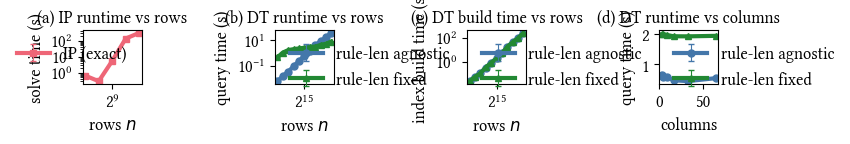

In [17]:
# Full text width for the 1x4 row; each panel is grid_width/4 wide and kept at
# the same 0.77 aspect ratio as the single plots.
grid_width_pt = 506.295
grid_fig_width = grid_width_pt * inches_per_pt
grid_fig_height = grid_fig_width / 4 * 0.77

fig, axs = plt.subplots(1, 4, figsize=(grid_fig_width, grid_fig_height))

# (a) IP runtime vs rows
ax = axs[0]
series(ax, data['ip'], 'n_rows', 'solve_sec', 'IP (exact)', CB_palette['CBred'], 's')
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xlabel('rows $n$'); ax.set_ylabel('solve time (s)')
ax.set_title('(a) IP runtime vs rows')
ax.legend(frameon=False)

# (b) DT runtime vs rows
ax = axs[1]
series(ax, data['agn_rows'], 'n_rows', 'query_sec', 'rule-len agnostic', CB_palette['CBblue'], 'o')
series(ax, data['fix_rows'], 'n_rows', 'query_sec', 'rule-len fixed', CB_palette['CBgreen'], '^')
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xlabel('rows $n$'); ax.set_ylabel('query time (s)')
ax.set_title('(b) DT runtime vs rows')
ax.legend(frameon=False)

# (c) DT index build time vs rows
ax = axs[2]
series(ax, data['agn_rows'], 'n_rows', 'build_sec', 'rule-len agnostic', CB_palette['CBblue'], 'o')
series(ax, data['fix_rows'], 'n_rows', 'build_sec', 'rule-len fixed', CB_palette['CBgreen'], '^')
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xlabel('rows $n$'); ax.set_ylabel('index build time (s)')
ax.set_title('(c) DT build time vs rows')
ax.legend(frameon=False)

# (d) DT runtime vs columns
ax = axs[3]
series(ax, data['agn_cols'], 'n_cols', 'query_sec', 'rule-len agnostic', CB_palette['CBblue'], 'o')
series(ax, data['fix_cols'], 'n_cols', 'query_sec', 'rule-len fixed', CB_palette['CBgreen'], '^')
ax.set_xlabel('columns'); ax.set_ylabel('query time (s)')
ax.set_title('(d) DT runtime vs columns')
ax.legend(frameon=False)

save(fig, 'combined_1x4')